# Credit Card Fraud Detection

## 1. Business Problem

Credit card fraud detection is a highly imbalanced binary classification problem in which fraudulent transactions represent only a very small proportion of all transactions.

The objective of this project is to develop machine learning models capable of identifying fraudulent transactions while minimizing false alerts on legitimate transactions.

Because of the severe class imbalance, model performance will be evaluated using precision, recall, F1-score, ROC-AUC, and PR-AUC rather than relying solely on accuracy.

The project will compare Logistic Regression, Random Forest, and XGBoost models using a leakage-free machine learning pipeline.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE

import xgboost as xgb

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 3. Load Dataset

In [2]:
df = pd.read_csv("creditcard.csv")

print(df.shape)

(284807, 31)


In [3]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## 4. Initial Dataset Inspection

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 284807
Number of columns: 31


In [6]:
print("Column names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum().sum())
print("\nDuplicate rows:")
print(df.duplicated().sum())
print("\nTarget distribution:")
print(df["Class"].value_counts())
print("\nTarget distribution (%):")
print(df["Class"].value_counts(normalize=True) * 100)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values:
0

Duplicate rows:
1081

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Target distribution (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


### Initial Data Quality Findings

The dataset contains 284,807 transactions across 31 features. No missing values were found.

However, 1,081 duplicate records were identified. These duplicate records will be removed before further analysis to avoid giving repeated transactions disproportionate influence during model training.

In [7]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows identified: {duplicate_count:,}")

df = df.drop_duplicates().copy()

print(f"Dataset shape after removing duplicates: {df.shape}")

Duplicate rows identified: 1,081
Dataset shape after removing duplicates: (283726, 31)


## 5. Exploratory Data Analysis

### 5.1 Class Distribution

The target variable `Class` indicates whether a transaction is legitimate (`0`) or fraudulent (`1`).

The dataset is highly imbalanced, with fraudulent transactions representing only a very small proportion of all transactions. This imbalance makes accuracy an unreliable standalone metric and motivates the use of precision, recall, F1-score and PR-AUC during model evaluation.

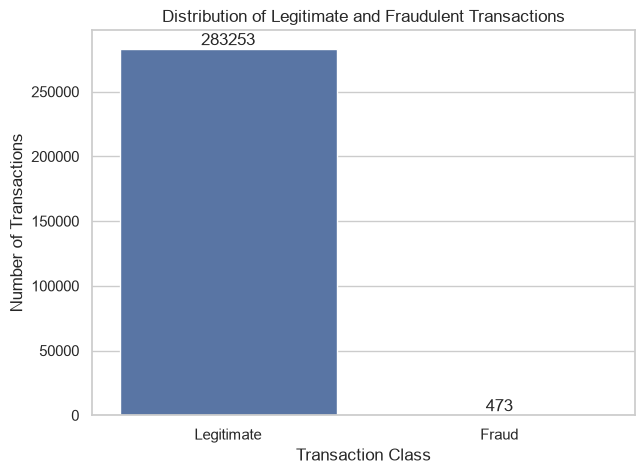

Legitimate transactions: 283,253
Fraudulent transactions: 473
Fraud rate: 0.1667%


In [8]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    legend=False
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.show()
fraud_rate = df["Class"].mean() * 100

print(f"Legitimate transactions: {class_counts[0]:,}")
print(f"Fraudulent transactions: {class_counts[1]:,}")
print(f"Fraud rate: {fraud_rate:.4f}%")

After removing duplicate records, the dataset contains 283,726 transactions, including 473 fraudulent transactions. Fraudulent transactions account for approximately 0.17% of the cleaned dataset, highlighting the severe class imbalance that must be addressed during model development.

### 5.2 Transaction Amount Analysis

The `Amount` feature represents the transaction value. Understanding its distribution is useful because transaction size may differ between legitimate and fraudulent transactions.

Extreme values are not automatically removed because unusually large transactions may contain useful information for fraud detection.

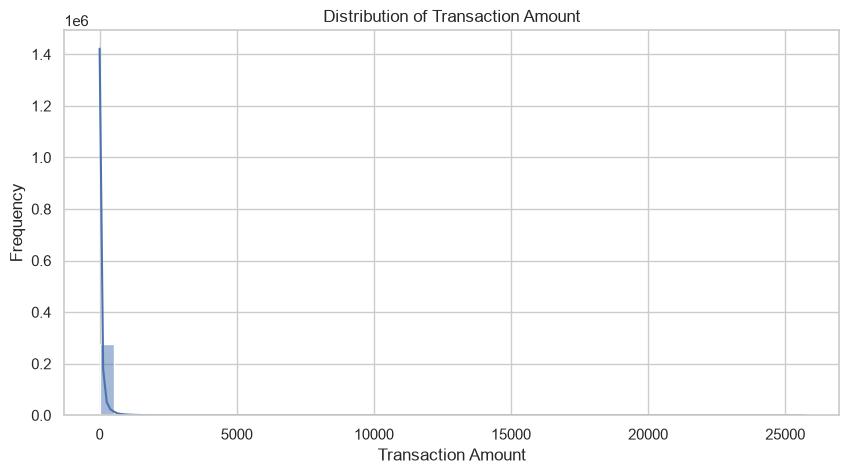

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

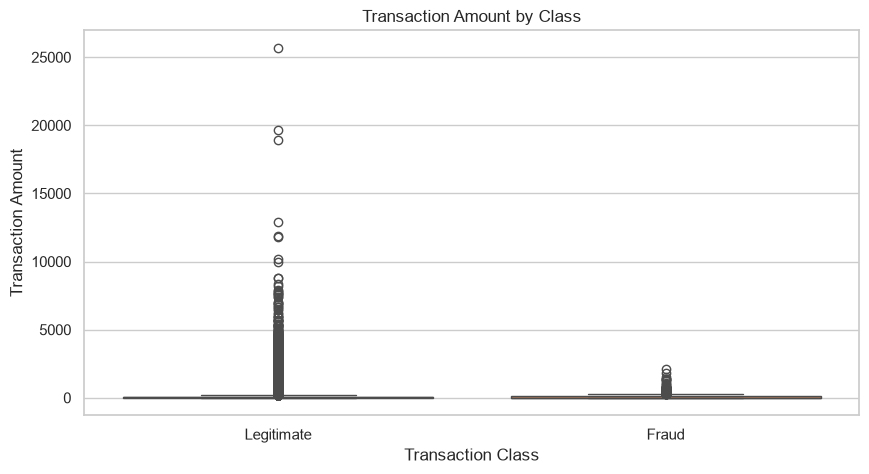

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    hue="Class",
    legend=False
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.show()

In [11]:
amount_summary = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

amount_summary.index = ["Legitimate", "Fraud"]

amount_summary

,count,mean,median,std,min,max
Legitimate,283253,88.413575,22.00,250.379023,0.0,25691.16
Fraud,473,123.871860,9.82,260.211041,0.0,2125.87


### 5.3 Transaction Time Analysis

The `Time` feature records the elapsed time in seconds from the first transaction.

For interpretability, it is converted into an approximate hour-of-day representation. This allows us to investigate whether fraud rates vary across different periods of the day.

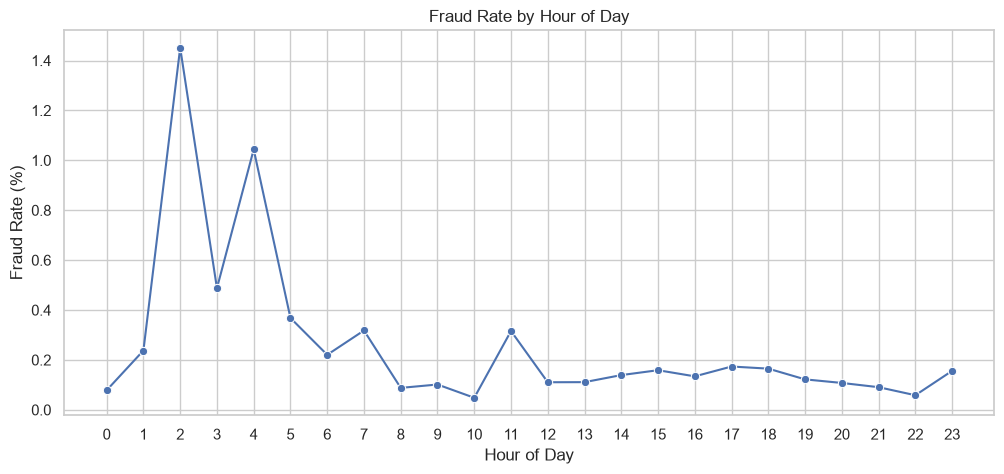

In [12]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)
hourly_fraud_rate = (
    df.groupby("Hour")["Class"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_fraud_rate.index,
    y=hourly_fraud_rate.values,
    marker="o"
)

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))

plt.show()

### 5.4 Transaction Amount Distribution by Class

The transaction amount is compared across legitimate and fraudulent transactions to identify differences in their distributions.

Extreme transaction amounts are retained in the dataset because they may contain useful information for fraud detection. The 99th percentile is used only to improve visualization and does not remove or modify any observations used for model training.

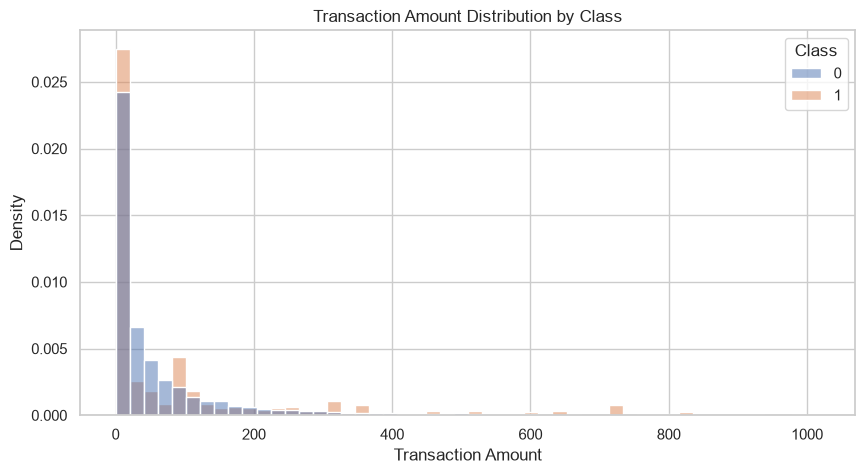

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Amount"] <= df["Amount"].quantile(0.99)],
    x="Amount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()

### 5.5 Feature Correlation with Fraud

The dataset contains anonymized PCA-transformed features (`V1`–`V28`). While their original business meaning is unavailable, their statistical relationship with the target can still be examined.

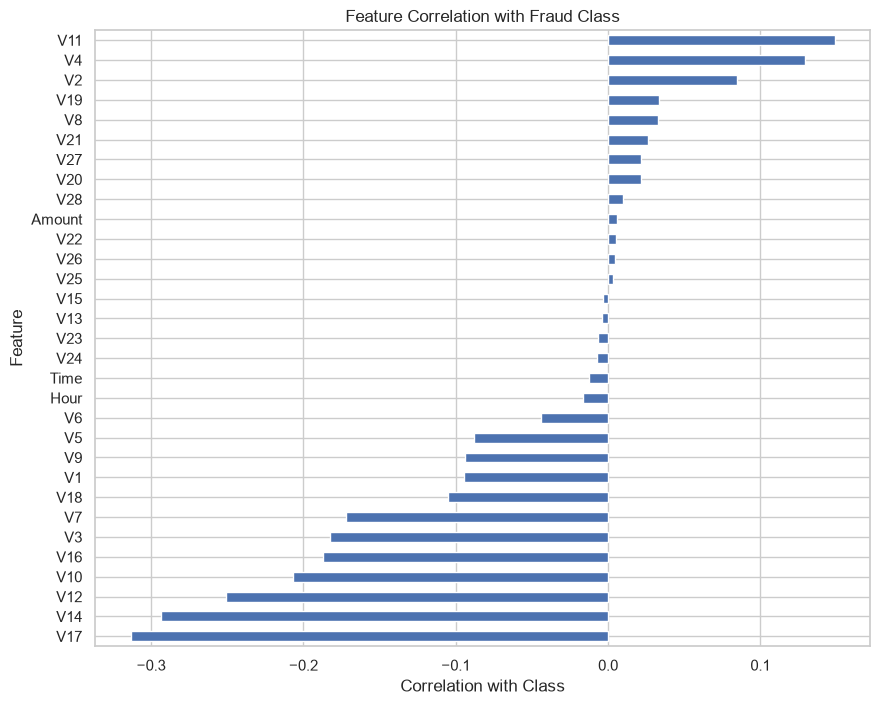

In [14]:
correlation_with_target = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values()
)

plt.figure(figsize=(10, 8))

correlation_with_target.plot(kind="barh")

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")

plt.show()

In [15]:
print("Top 5 positive correlations with fraud:")
print(correlation_with_target.tail(5).sort_values(ascending=False))

print("\nTop 5 negative correlations with fraud:")
print(correlation_with_target.head(5))

Top 5 positive correlations with fraud:
V11    0.149067
V4     0.129326
V2     0.084624
V19    0.033631
V8     0.033068
Name: Class, dtype: float64

Top 5 negative correlations with fraud:
V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64


The correlation analysis shows that several anonymized PCA-transformed features have relatively stronger statistical associations with the fraud class. V11, V4, and V2 show the strongest positive correlations, while V17, V14, and V12 show the strongest negative correlations. These relationships are exploratory and should not be interpreted as causal effects or direct business meanings.

## 6. Data Preprocessing

### 6.1 Separating Features and Target

The `Class` column is the target variable, where `0` represents a legitimate transaction and `1` represents a fraudulent transaction.

All remaining columns are used as input features.

In [16]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (283726, 31)
Target shape: (283726,)


In [17]:
X = X.drop("Hour", axis=1)

### 6.2 Train/Test Split

The dataset is split into training and testing sets before any scaling or oversampling is performed.

Stratified sampling is used to preserve the original proportion of fraudulent and legitimate transactions in both sets.

The test set will remain completely untouched during preprocessing and model training so that it provides an unbiased evaluation of model performance.

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training set: (226980, 30)
Test set: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Test class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


### 6.3 Feature Scaling

The `Time` and `Amount` features have different numerical scales compared with the PCA-transformed features. Standardization is therefore applied before model training.

To prevent data leakage, the scaler is fitted only on the training data and then used to transform both the training and test sets.

The test data is never used to fit the scaler.

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (226980, 30)
Scaled test shape: (56746, 30)


## 7. Handling Class Imbalance

The cleaned dataset contains only a small number of fraudulent transactions compared with legitimate transactions.

To address this imbalance during model training, SMOTE (Synthetic Minority Over-sampling Technique) will be applied to the training data.

SMOTE will be applied only after the train/test split and only to the training data. The test set will retain its original class distribution so that model performance can be evaluated on data representative of the real class imbalance.

### 7.1 Applying SMOTE to Training Data

In [20]:
smote = SMOTE(
    sampling_strategy=0.5,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

# Reduce memory usage
X_train_smote = X_train_smote.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining data shape after SMOTE:")
print(X_train_smote.shape)

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    113301
Name: count, dtype: int64

Training data shape after SMOTE:
(339903, 30)


## 8. Model Development

Three classification models are trained and compared:

1. Logistic Regression — used as a baseline model.
2. Random Forest — a tree-based ensemble model capable of capturing nonlinear relationships.
3. XGBoost — a gradient boosting model commonly used for structured/tabular classification problems.

All models are trained using the SMOTE-balanced training data and evaluated on the original, untouched test set.

### 8.1 Logistic Regression

Logistic Regression is used as a baseline classification model. It provides a simple and interpretable benchmark against which the more complex tree-based models can be compared.

In [21]:
logistic_model = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=500,
    solver="lbfgs"
)

logistic_model.fit(
    X_train_smote,
    y_train_smote
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### 8.2 Random Forest

Random Forest is an ensemble of decision trees that can capture nonlinear relationships between features and the target. It is trained on the balanced training data to improve its ability to learn patterns associated with the minority fraud class.

In [22]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

print("Random Forest training completed.")

Random Forest training completed.


### 8.3 HistGradientBoosting

HistGradientBoosting is used as a third classification model to provide an additional tree-based approach for fraud detection.

The model is trained on the SMOTE-resampled training data while the original test set remains untouched. This allows its performance to be compared fairly with Logistic Regression and Random Forest using the same evaluation metrics.

In [23]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=RANDOM_STATE
)

hgb_model.fit(
    X_train_smote,
    y_train_smote
)

print("HistGradientBoosting training completed.")

HistGradientBoosting training completed.


## 9. Model Evaluation

The trained models are evaluated on the untouched test set to measure their ability to detect previously unseen fraudulent transactions.

Since the dataset is highly imbalanced, accuracy alone is not sufficient to assess model performance. Precision, recall, F1-score, ROC-AUC, and PR-AUC are used to provide a more meaningful evaluation of fraud detection performance.

### 9.1 Generating Predictions

Predictions and probability estimates are generated for the untouched test set using all three trained models. The predicted probabilities will be used to calculate threshold-based metrics such as ROC-AUC and PR-AUC.

In [24]:
# Generate predictions for Logistic Regression
y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Generate predictions for Random Forest
y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Generate predictions for HistGradientBoosting
y_pred_hgb = hgb_model.predict(X_test_scaled)
y_prob_hgb = hgb_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


### 9.2 Performance Comparison

The models are compared using precision, recall, F1-score, ROC-AUC, and PR-AUC. These metrics provide a more informative assessment of fraud detection performance than accuracy alone, particularly because fraudulent transactions are highly underrepresented in the dataset.

In [25]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(y_true, y_pred, y_prob):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }

results = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_test, y_pred_lr, y_prob_lr
    ),
    "Random Forest": evaluate_model(
        y_test, y_pred_rf, y_prob_rf
    ),
    "HistGradientBoosting": evaluate_model(
        y_test, y_pred_hgb, y_prob_hgb
    )
}).T

results.round(4)

,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Logistic Regression,0.1077,0.8737,0.1917,0.9646,0.7098
Random Forest,0.8111,0.7684,0.7892,0.9769,0.7998
HistGradientBoosting,0.6311,0.8105,0.7097,0.9739,0.7983


### 9.3 Confusion Matrix

Confusion matrices are used to examine the number of correctly and incorrectly classified legitimate and fraudulent transactions.

For fraud detection, particular attention is given to false negatives, where fraudulent transactions are incorrectly classified as legitimate, and false positives, where legitimate transactions are incorrectly flagged as fraudulent.

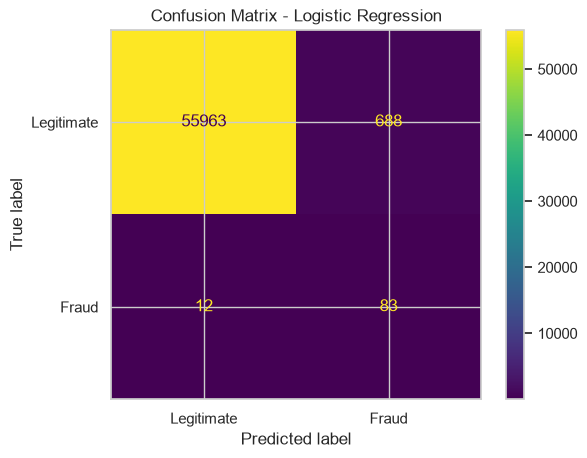

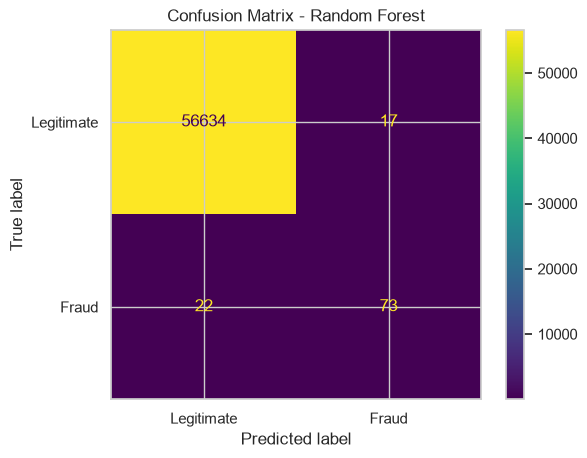

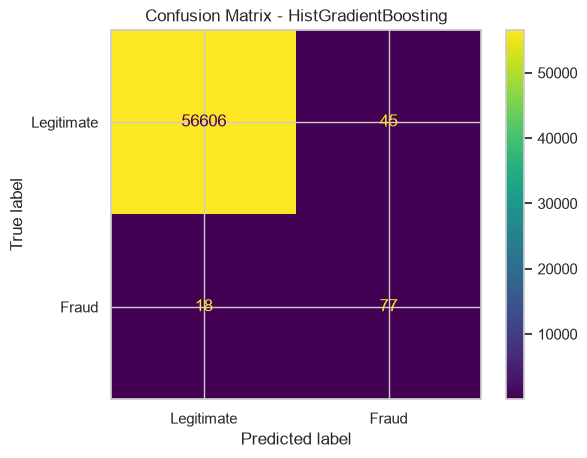

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "HistGradientBoosting": y_pred_hgb
}

for model_name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"]
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

### 9.4 ROC Curve

The Receiver Operating Characteristic (ROC) curve shows the trade-off between the true positive rate and false positive rate across different classification thresholds.

The Area Under the ROC Curve (ROC-AUC) summarizes the model's ability to distinguish between legitimate and fraudulent transactions. A higher ROC-AUC indicates better discrimination between the two classes.

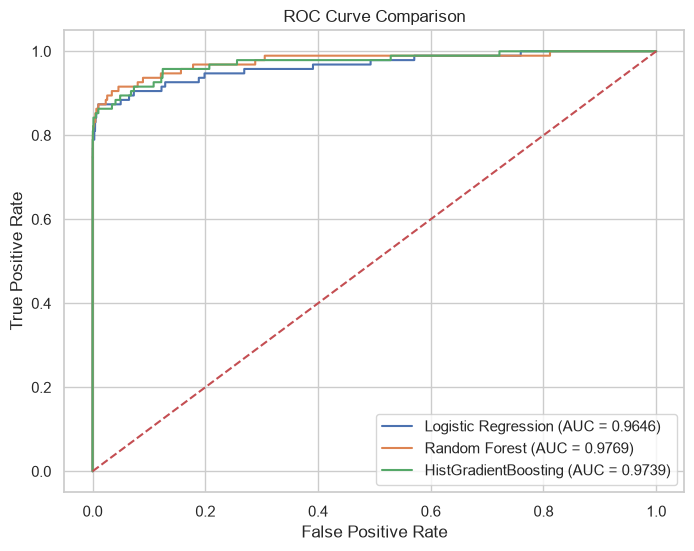

In [27]:
from sklearn.metrics import roc_curve, auc

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_hgb, tpr_hgb, _ = roc_curve(y_test, y_prob_hgb)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr, tpr_lr,
    label=f"Logistic Regression (AUC = {auc(fpr_lr, tpr_lr):.4f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc(fpr_rf, tpr_rf):.4f})"
)

plt.plot(
    fpr_hgb, tpr_hgb,
    label=f"HistGradientBoosting (AUC = {auc(fpr_hgb, tpr_hgb):.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

### 9.5 Precision-Recall Curve

The Precision-Recall curve shows the trade-off between precision and recall across different classification thresholds.

PR-AUC is particularly informative for this project because fraudulent transactions represent a very small proportion of the dataset. It therefore provides a more focused view of how effectively the models identify fraudulent transactions while limiting false positives.

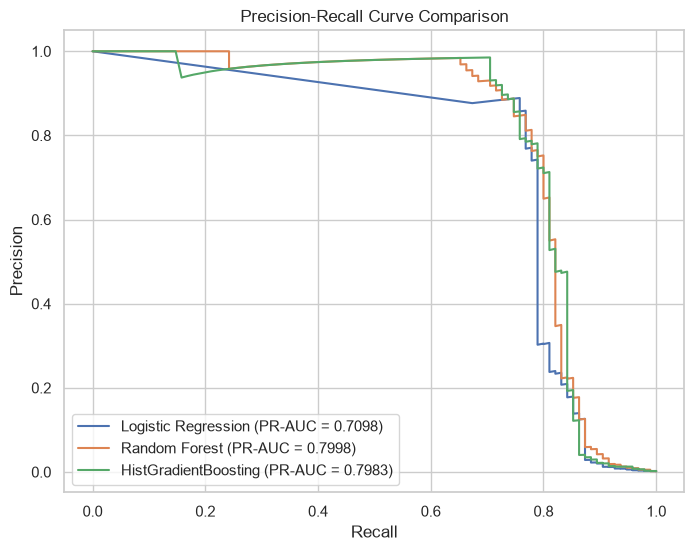

In [28]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)
precision_hgb, recall_hgb, _ = precision_recall_curve(y_test, y_prob_hgb)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lr,
    precision_lr,
    label=f"Logistic Regression (PR-AUC = {average_precision_score(y_test, y_prob_lr):.4f})"
)

plt.plot(
    recall_rf,
    precision_rf,
    label=f"Random Forest (PR-AUC = {average_precision_score(y_test, y_prob_rf):.4f})"
)

plt.plot(
    recall_hgb,
    precision_hgb,
    label=f"HistGradientBoosting (PR-AUC = {average_precision_score(y_test, y_prob_hgb):.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()

### 9.6 Feature Importance

Feature importance from the Random Forest model is examined to identify which input features contribute most to the model's fraud predictions.

The dataset contains anonymized PCA-transformed features (`V1`–`V28`), so these importance values indicate model-level statistical relevance rather than specific real-world business factors.

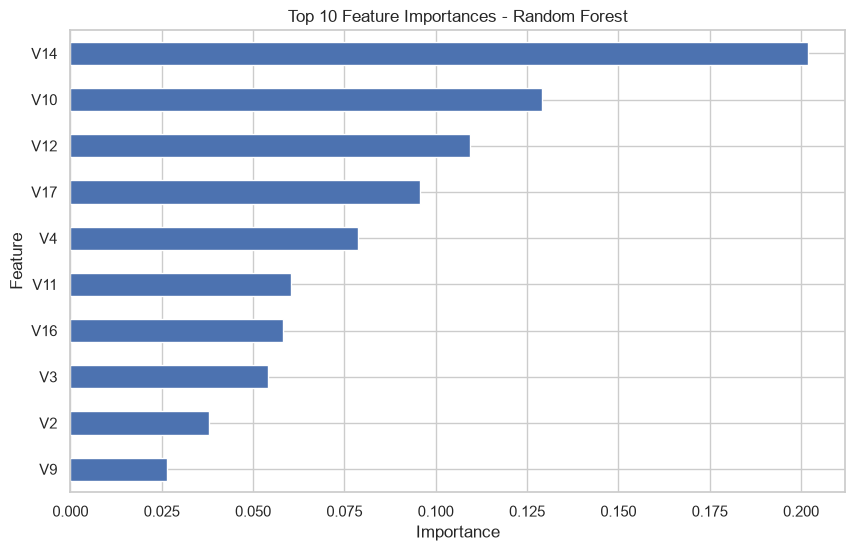

In [29]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### 9.7 Model Comparison Summary

The three models demonstrate different trade-offs between precision and recall.

Logistic Regression achieves the highest recall, identifying 87.37% of fraudulent transactions, but produces a substantially higher number of false positives.

Random Forest provides the highest precision, F1-score, and ROC-AUC among the evaluated models, while maintaining a recall of 76.84%.

HistGradientBoosting achieves a recall of 81.05% and a PR-AUC of 0.7983, showing competitive performance with Random Forest.

The results demonstrate that model selection for fraud detection depends on the desired balance between detecting fraudulent transactions and limiting false alerts.

### 9.8 Final Model Comparison

The model results are summarized below to compare their performance across the key evaluation metrics.

| Model | Precision | Recall | F1-Score | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.1077 | 0.8737 | 0.1917 | 0.9646 | 0.7098 |
| Random Forest | 0.8111 | 0.7684 | 0.7892 | 0.9769 | 0.7998 |
| HistGradientBoosting | 0.6311 | 0.8105 | 0.7097 | 0.9739 | 0.7983 |

The results highlight the trade-off between fraud detection recall and the number of false positive alerts generated by each model.

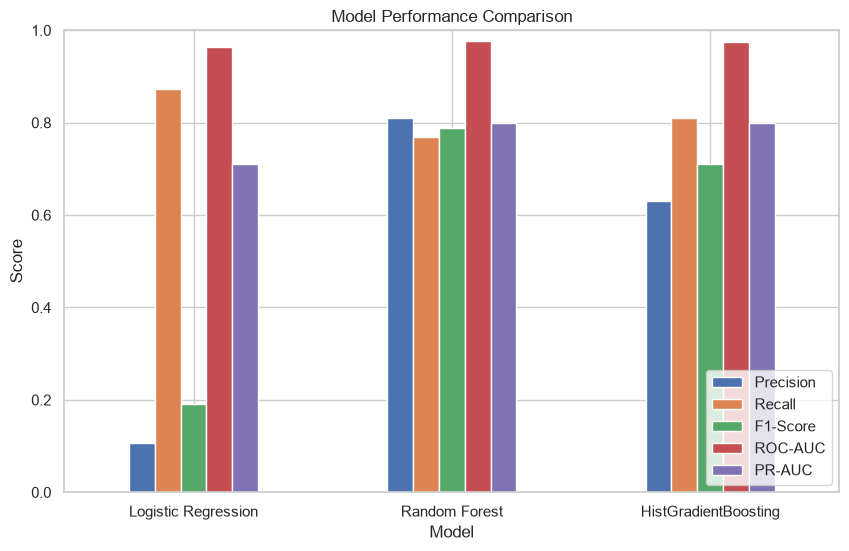

In [30]:
results.plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

## 10. Key Findings

- The dataset is highly imbalanced, with fraudulent transactions representing only a small fraction of all transactions.
- Logistic Regression achieved the highest recall of 87.37%, but its precision was considerably lower at 10.77%, resulting in a large number of false positives.
- Random Forest achieved a precision of 81.11%, recall of 76.84%, F1-score of 78.92%, ROC-AUC of 97.69%, and PR-AUC of 79.98%.
- HistGradientBoosting achieved a recall of 81.05% and PR-AUC of 79.83%, providing competitive performance with Random Forest.
- The results demonstrate that fraud detection requires balancing the identification of fraudulent transactions against false alerts rather than relying on accuracy alone.
- Feature importance analysis showed that V14, V10, V12, V17, and V4 were among the most influential features for the Random Forest model. Since the dataset uses anonymized PCA-transformed features, these values cannot be directly interpreted as specific business factors.

## 11. Conclusion

This project developed and evaluated machine learning models for credit card fraud detection using a highly imbalanced transaction dataset.

The workflow included data cleaning, exploratory data analysis, stratified train-test splitting, feature scaling, controlled SMOTE-based oversampling of the training data, model training, and evaluation using precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

The evaluation shows that different models provide different trade-offs between detecting fraudulent transactions and limiting false positive alerts. Random Forest achieved the highest precision, F1-score, ROC-AUC, and PR-AUC among the evaluated models, while Logistic Regression provided the highest recall.

The project demonstrates the importance of using appropriate evaluation metrics and leakage-free preprocessing when working with highly imbalanced fraud detection problems.